In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
import pickle

In [4]:
ss=StandardScaler()
ss

,copy,True
,with_mean,True
,with_std,True


In [6]:
data=pd.read_csv("/home/ubuntu/ds/dl/ann/Churn_Modelling.csv")
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Preprocessing 

In [7]:
df=data

In [8]:
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [9]:
df=df.drop(['RowNumber','CustomerId','Surname'],axis=1)

In [10]:
df

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


### Gender and geography columns need to be encoded 

In [11]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [12]:
df['Gender']=le.fit_transform(df['Gender'])  

In [13]:
#### Female to 0 , Male to 1 -- alphabatically 

In [14]:
df

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,0,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,0,41,1,83807.86,1,0,1,112542.58,0
2,502,France,0,42,8,159660.80,3,1,0,113931.57,1
3,699,France,0,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,0,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,1,39,5,0.00,2,1,0,96270.64,0
9996,516,France,1,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,0,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,1,42,3,75075.31,2,1,0,92888.52,1


In [15]:
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder()

In [18]:
ohe_geo=ohe.fit_transform(df[['Geography']])
ohe_geo=ohe_geo.toarray()
ohe_geo 

array([[1., 0., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       ...,
       [1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 0.]])

In [19]:
## alphabatically arranged --> france, germany , spain 

In [20]:
ohe.get_feature_names_out(['Geography'])

array(['Geography_France', 'Geography_Germany', 'Geography_Spain'],
      dtype=object)

In [21]:
ohe_geo_df=pd.DataFrame(ohe_geo,columns=ohe.get_feature_names_out(['Geography']))
ohe_geo_df

,Geography_France,Geography_Germany,Geography_Spain
0,1.0,0.0,0.0
1,0.0,0.0,1.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,0.0,0.0,1.0
...,...,...,...
9995,1.0,0.0,0.0
9996,1.0,0.0,0.0
9997,1.0,0.0,0.0
9998,0.0,1.0,0.0


In [22]:
df.drop(['Geography'],axis=1,inplace=True)

In [23]:
df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,0,42,2,0.00,1,1,1,101348.88,1
1,608,0,41,1,83807.86,1,0,1,112542.58,0
2,502,0,42,8,159660.80,3,1,0,113931.57,1
3,699,0,39,1,0.00,2,0,0,93826.63,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0


In [24]:
df1=pd.concat([df,ohe_geo_df],axis=1)
df1

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,1.0,0.0,0.0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0.0,0.0,1.0
2,502,0,42,8,159660.80,3,1,0,113931.57,1,1.0,0.0,0.0
3,699,0,39,1,0.00,2,0,0,93826.63,0,1.0,0.0,0.0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,1,39,5,0.00,2,1,0,96270.64,0,1.0,0.0,0.0
9996,516,1,35,10,57369.61,1,1,1,101699.77,0,1.0,0.0,0.0
9997,709,0,36,7,0.00,1,0,1,42085.58,1,1.0,0.0,0.0
9998,772,1,42,3,75075.31,2,1,0,92888.52,1,0.0,1.0,0.0


In [25]:
## Save the encoders and sscaler
with open('/home/ubuntu/ds/dl/ann/label_encoder_gender.pkl','wb') as file:
    pickle.dump(le,file)

with open('/home/ubuntu/ds/dl/ann/onehot_encoder_geo.pkl','wb') as file:
    pickle.dump(ohe,file)

## Prep for ANN

### Question to Answer -- whether a person decides to leave bank or not ?? : y = exited column 

In [26]:
y=df1['Exited']

In [27]:
X=df1.drop('Exited',axis=1)
X

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1.0,0.0,0.0
1,608,0,41,1,83807.86,1,0,1,112542.58,0.0,0.0,1.0
2,502,0,42,8,159660.80,3,1,0,113931.57,1.0,0.0,0.0
3,699,0,39,1,0.00,2,0,0,93826.63,1.0,0.0,0.0
4,850,0,43,2,125510.82,1,1,1,79084.10,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,1,39,5,0.00,2,1,0,96270.64,1.0,0.0,0.0
9996,516,1,35,10,57369.61,1,1,1,101699.77,1.0,0.0,0.0
9997,709,0,36,7,0.00,1,0,1,42085.58,1.0,0.0,0.0
9998,772,1,42,3,75075.31,2,1,0,92888.52,0.0,1.0,0.0


In [28]:
type(X),type(y)

(pandas.core.frame.DataFrame, pandas.core.series.Series)

In [29]:
tts=train_test_split
X_train,X_test,y_train,y_test=tts(X,y,test_size=0.2,random_state=42)

In [30]:
tts

<function sklearn.model_selection._split.train_test_split(*arrays, test_size=None, train_size=None, random_state=None, shuffle=True, stratify=None)>

In [31]:
X_train

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain
9254,686,1,32,6,0.00,2,1,1,179093.26,1.0,0.0,0.0
1561,632,1,42,4,119624.60,2,1,1,195978.86,0.0,1.0,0.0
1670,559,1,24,3,114739.92,1,1,0,85891.02,0.0,0.0,1.0
6087,561,0,27,9,135637.00,1,1,0,153080.40,1.0,0.0,0.0
6669,517,1,56,9,142147.32,1,0,0,39488.04,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
5734,768,1,54,8,69712.74,1,1,1,69381.05,1.0,0.0,0.0
5191,682,0,58,1,0.00,1,1,1,706.50,1.0,0.0,0.0
5390,735,0,38,1,0.00,3,0,0,92220.12,1.0,0.0,0.0
860,667,1,43,8,190227.46,1,1,0,97508.04,1.0,0.0,0.0


In [32]:
ss

,copy,True
,with_mean,True
,with_std,True


In [33]:
X_train=ss.fit_transform(X_train)
X_train

array([[ 0.35649971,  0.91324755, -0.6557859 , ...,  1.00150113,
        -0.57946723, -0.57638802],
       [-0.20389777,  0.91324755,  0.29493847, ..., -0.99850112,
         1.72572313, -0.57638802],
       [-0.96147213,  0.91324755, -1.41636539, ..., -0.99850112,
        -0.57946723,  1.73494238],
       ...,
       [ 0.86500853, -1.09499335, -0.08535128, ...,  1.00150113,
        -0.57946723, -0.57638802],
       [ 0.15932282,  0.91324755,  0.3900109 , ...,  1.00150113,
        -0.57946723, -0.57638802],
       [ 0.47065475,  0.91324755,  1.15059039, ..., -0.99850112,
         1.72572313, -0.57638802]])

In [34]:
X_test.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain
6252,596,1,32,3,96709.07,2,0,0,41788.37,0.0,1.0,0.0
4684,623,1,43,1,0.00,2,1,1,146379.30,1.0,0.0,0.0
1731,601,0,44,4,0.00,2,1,0,58561.31,0.0,0.0,1.0
4742,506,1,59,8,119152.10,2,1,1,170679.74,0.0,1.0,0.0
4521,560,0,27,7,124995.98,1,1,1,114669.79,0.0,0.0,1.0


In [35]:
X_test=ss.transform(X_test)
X_test

array([[-0.57749609,  0.91324755, -0.6557859 , ..., -0.99850112,
         1.72572313, -0.57638802],
       [-0.29729735,  0.91324755,  0.3900109 , ...,  1.00150113,
        -0.57946723, -0.57638802],
       [-0.52560743, -1.09499335,  0.48508334, ..., -0.99850112,
        -0.57946723,  1.73494238],
       ...,
       [ 0.81311987, -1.09499335,  0.77030065, ...,  1.00150113,
        -0.57946723, -0.57638802],
       [ 0.41876609,  0.91324755, -0.94100321, ...,  1.00150113,
        -0.57946723, -0.57638802],
       [-0.24540869,  0.91324755,  0.00972116, ..., -0.99850112,
         1.72572313, -0.57638802]])

In [36]:
## creating pickle of standard scalar 
with open ('/home/ubuntu/ds/dl/ann/StandardScaler.pkl','wb') as file:
    pickle.dump(ss,file)

In [37]:
df1.columns

Index(['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
       'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited',
       'Geography_France', 'Geography_Germany', 'Geography_Spain'],
      dtype='object')

## ANN Implementation 

In [38]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping,TensorBoard
import datetime

I0000 00:00:1782989020.986737    1369 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1782989022.714644    1369 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1782989026.691085    1369 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [41]:
type(X_train)

numpy.ndarray

In [42]:
X_train

array([[ 0.35649971,  0.91324755, -0.6557859 , ...,  1.00150113,
        -0.57946723, -0.57638802],
       [-0.20389777,  0.91324755,  0.29493847, ..., -0.99850112,
         1.72572313, -0.57638802],
       [-0.96147213,  0.91324755, -1.41636539, ..., -0.99850112,
        -0.57946723,  1.73494238],
       ...,
       [ 0.86500853, -1.09499335, -0.08535128, ...,  1.00150113,
        -0.57946723, -0.57638802],
       [ 0.15932282,  0.91324755,  0.3900109 , ...,  1.00150113,
        -0.57946723, -0.57638802],
       [ 0.47065475,  0.91324755,  1.15059039, ..., -0.99850112,
         1.72572313, -0.57638802]])

In [39]:
X_train.shape #input

(8000, 12)

In [40]:
(X_train.shape[1],)

(12,)

In [43]:
import tensorflow as tf

print(tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

2.21.0
GPUs: []


E0000 00:00:1782989105.402271    1369 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [44]:
## ann model building 
model=Sequential([
    Dense(64,activation='relu',input_shape=(X_train.shape[1],)), # HL1
    Dense(32,activation='relu'), #HL2
    Dense(1,activation='sigmoid')] #Output Layer
)

/home/ubuntu/anaconda3/envs/ds2/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [45]:
model

<Sequential name=sequential, built=True>

In [46]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
## add optimizers to the model 
opt=tf.keras.optimizers.Adam(learning_rate=0.01)
opt

In [48]:
## loss 
loss=tf.keras.losses.BinaryCrossentropy()
loss

<LossFunctionWrapper(<function binary_crossentropy at 0x7d2a4e7aeb90>, kwargs={'from_logits': False, 'label_smoothing': 0.0, 'axis': -1})>

In [49]:
# model compilation 
model.compile(
    optimizer=opt, 
    loss='BinaryCrossentropy',
    metrics=['accuracy'])

In [50]:
## Set Tensorboard
from tensorflow.keras.callbacks import EarlyStopping,TensorBoard

log_dir="/home/ubuntu/ds/dl/logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorflow_callback=TensorBoard(log_dir=log_dir,histogram_freq=1)

In [51]:
## setting up callback
early_stopping_callback=EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True)

In [52]:
## Train model 
history=model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=100,callbacks=[early_stopping_callback,tensorflow_callback])

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8303 - loss: 0.4044 - val_accuracy: 0.8560 - val_loss: 0.3453
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8551 - loss: 0.3569 - val_accuracy: 0.8605 - val_loss: 0.3394
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8561 - loss: 0.3464 - val_accuracy: 0.8595 - val_loss: 0.3505
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8579 - loss: 0.3418 - val_accuracy: 0.8570 - val_loss: 0.3466
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8615 - loss: 0.3390 - val_accuracy: 0.8645 - val_loss: 0.3360
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8616 - loss: 0.3365 - val_accuracy: 0.8580 - val_loss: 0.3415
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8658 - loss: 0.3359 - val_accuracy: 0.8610 - val_loss: 0.3446
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8605 - loss: 0.3326 - val_accu

In [53]:
%cd /home/ubuntu/ds/dl/ann/
model.save('model.h5')

/home/ubuntu/anaconda3/envs/ds2/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


/home/ubuntu/ds/dl/ann


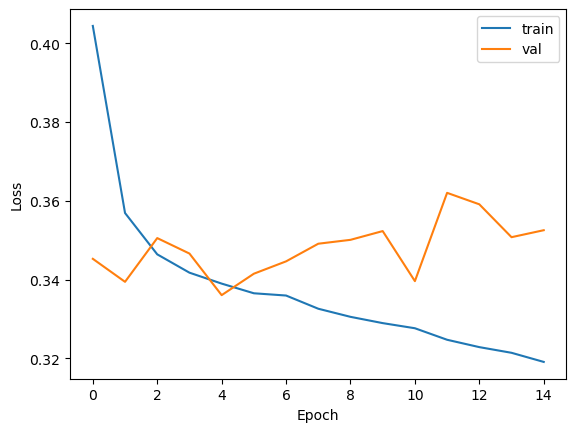

In [54]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['train', 'val'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

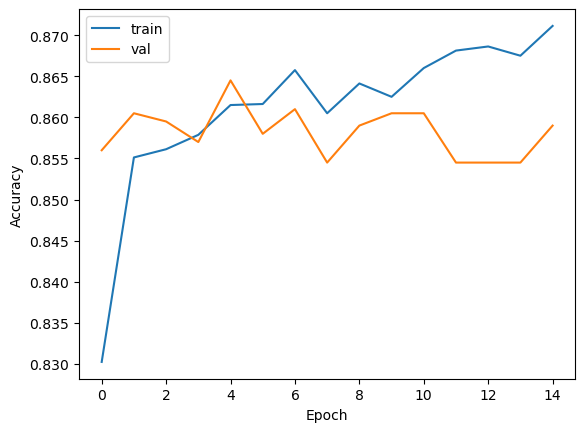

In [55]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['train', 'val'])
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()

## Perfoming predictions on a new input 

In [56]:
### input 
input_data = {
    'CreditScore': 600,
    'Geography': 'France',
    'Gender': 'Male',
    'Age': 40,
    'Tenure': 3,
    'Balance': 60000,
    'NumOfProducts': 2,
    'HasCrCard': 1,
    'IsActiveMember': 1,
    'EstimatedSalary': 50000
}

In [57]:
type(input_data)

dict

In [58]:
input_df=pd.DataFrame([input_data])
input_df

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,600,France,Male,40,3,60000,2,1,1,50000


In [59]:
## geography encode 
geo_encode=ohe.transform([[input_data['Geography']]])

/home/ubuntu/anaconda3/envs/ds2/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but OneHotEncoder was fitted with feature names
  warnings.warn(


In [60]:
geo_encode=geo_encode.toarray()
geo_encode

array([[1., 0., 0.]])

In [61]:
geo_encode_df=pd.DataFrame(geo_encode,columns=ohe.get_feature_names_out(['Geography']))
geo_encode_df

,Geography_France,Geography_Germany,Geography_Spain
0,1.0,0.0,0.0


In [62]:
input_df['Gender']=le.transform(input_df['Gender'])
input_df

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,600,France,1,40,3,60000,2,1,1,50000


In [63]:
final_input=pd.concat([input_df.drop(['Geography'],axis=1),geo_encode_df],axis=1)

In [64]:
final_input

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain
0,600,1,40,3,60000,2,1,1,50000,1.0,0.0,0.0


In [65]:
input_scaled=ss.transform(final_input)
input_scaled

array([[-0.53598516,  0.91324755,  0.10479359, -0.69539349, -0.25781119,
         0.80843615,  0.64920267,  0.97481699, -0.87683221,  1.00150113,
        -0.57946723, -0.57638802]])

### Prediction

In [66]:
predict=model.predict(input_scaled)
predict

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


array([[0.03445876]], dtype=float32)

In [72]:
prediction=predict[0][0]

In [73]:
prediction

0.03445876

In [98]:
### Since prob < 0.5 .. binary classficcation ... customer not likely to churn 

# Regression problem 

In [74]:
y=df1['EstimatedSalary']
y

0       101348.88
1       112542.58
2       113931.57
3        93826.63
4        79084.10
          ...    
9995     96270.64
9996    101699.77
9997     42085.58
9998     92888.52
9999     38190.78
Name: EstimatedSalary, Length: 10000, dtype: float64

In [76]:
type(y)

pandas.core.series.Series

In [77]:
X=df1.drop('EstimatedSalary',axis=1)
X

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited,Geography_France,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,1,1.0,0.0,0.0
1,608,0,41,1,83807.86,1,0,1,0,0.0,0.0,1.0
2,502,0,42,8,159660.80,3,1,0,1,1.0,0.0,0.0
3,699,0,39,1,0.00,2,0,0,0,1.0,0.0,0.0
4,850,0,43,2,125510.82,1,1,1,0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,1,39,5,0.00,2,1,0,0,1.0,0.0,0.0
9996,516,1,35,10,57369.61,1,1,1,0,1.0,0.0,0.0
9997,709,0,36,7,0.00,1,0,1,1,1.0,0.0,0.0
9998,772,1,42,3,75075.31,2,1,0,1,0.0,1.0,0.0


In [78]:
type(X)

pandas.core.frame.DataFrame

In [80]:
from sklearn.model_selection import train_test_split 
tts2=train_test_split

In [82]:
X_train,X_test,y_train,y_test=tts2(X,y,random_state=42,test_size=0.2)

In [86]:
for i in [X_train,X_test,y_train,y_test]:
    print(i.shape)

(8000, 12)
(2000, 12)
(8000,)
(2000,)


In [88]:
X_train, X_test

(      CreditScore  Gender  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
 9254          686       1   32       6       0.00              2          1   
 1561          632       1   42       4  119624.60              2          1   
 1670          559       1   24       3  114739.92              1          1   
 6087          561       0   27       9  135637.00              1          1   
 6669          517       1   56       9  142147.32              1          0   
 ...           ...     ...  ...     ...        ...            ...        ...   
 5734          768       1   54       8   69712.74              1          1   
 5191          682       0   58       1       0.00              1          1   
 5390          735       0   38       1       0.00              3          0   
 860           667       1   43       8  190227.46              1          1   
 7270          697       1   51       1  147910.30              1          1   
 
       IsActiveMember  Exited  Geograp

In [89]:
X_train=ss.fit_transform(X_train)
X_test=ss.transform(X_test)

In [90]:
X_train, X_test

(array([[ 0.35649971,  0.91324755, -0.6557859 , ...,  1.00150113,
         -0.57946723, -0.57638802],
        [-0.20389777,  0.91324755,  0.29493847, ..., -0.99850112,
          1.72572313, -0.57638802],
        [-0.96147213,  0.91324755, -1.41636539, ..., -0.99850112,
         -0.57946723,  1.73494238],
        ...,
        [ 0.86500853, -1.09499335, -0.08535128, ...,  1.00150113,
         -0.57946723, -0.57638802],
        [ 0.15932282,  0.91324755,  0.3900109 , ...,  1.00150113,
         -0.57946723, -0.57638802],
        [ 0.47065475,  0.91324755,  1.15059039, ..., -0.99850112,
          1.72572313, -0.57638802]]),
 array([[-0.57749609,  0.91324755, -0.6557859 , ..., -0.99850112,
          1.72572313, -0.57638802],
        [-0.29729735,  0.91324755,  0.3900109 , ...,  1.00150113,
         -0.57946723, -0.57638802],
        [-0.52560743, -1.09499335,  0.48508334, ..., -0.99850112,
         -0.57946723,  1.73494238],
        ...,
        [ 0.81311987, -1.09499335,  0.77030065, ...,  

In [91]:
X_train.shape[1]

12

In [93]:
model=Sequential()
model.add(Dense(64,activation='relu',input_shape=[12]))
model.add(Dense(32,activation='relu'))
model.add(Dense(1))

In [95]:
model.compile(optimizer='adam',loss='mean_absolute_error',metrics=['mae'])

In [97]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

In [99]:
# Set up Early Stopping
early_stopping_callback = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

In [100]:
# Training neural network
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    callbacks=[early_stopping_callback, tensorboard_callback]
)

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 100390.6719 - mae: 100390.6719 - val_loss: 98564.4844 - val_mae: 98564.4844
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 99796.1094 - mae: 99796.1094 - val_loss: 97351.5547 - val_mae: 97351.5547
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 97669.1406 - mae: 97669.1406 - val_loss: 94213.2969 - val_mae: 94213.2969
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 93408.4062 - mae: 93408.4062 - val_loss: 88827.9062 - val_mae: 88827.9062
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 87033.0391 - mae: 87033.0391 - val_loss: 81661.4062 - val_mae: 81661.4062
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 79121.4922 - mae: 79121.4922 - val_loss: 73553.1172 - val_mae: 73553.1172
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 70842.1172 - mae: 70842.1172 - val_loss: 65972.5781 - val_mae: 65972.5781
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step 

In [101]:
%cd /home/ubuntu/ds/dl/ann/
model.save('model_regression.h5')

/home/ubuntu/anaconda3/envs/ds2/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


/home/ubuntu/ds/dl/ann


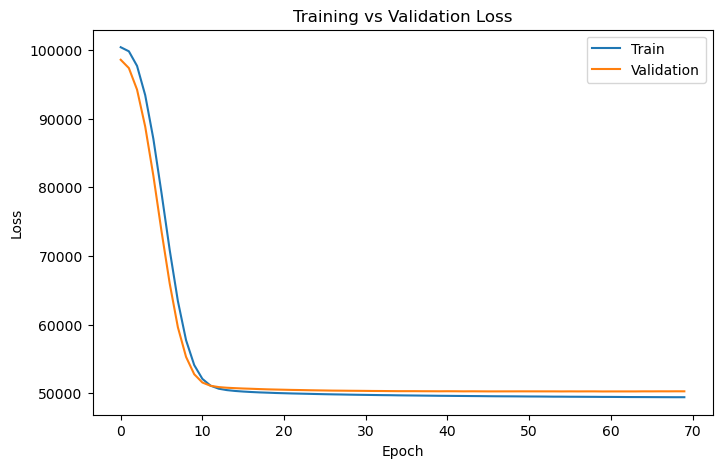

In [110]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend(['Train', 'Validation'])

plt.show()

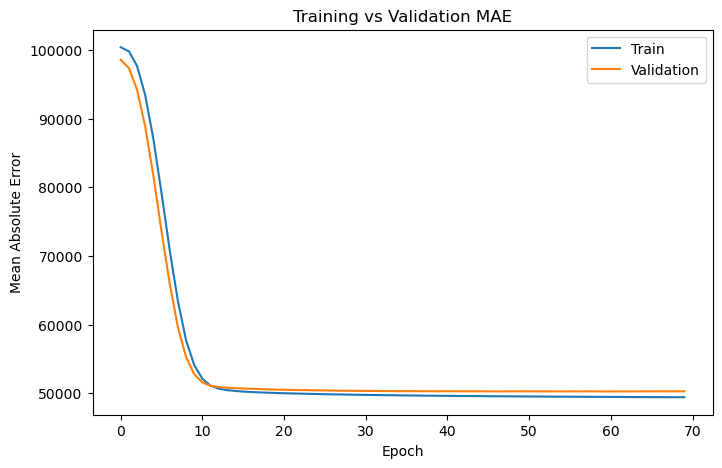

In [109]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])

plt.xlabel('Epoch')
plt.ylabel('Mean Absolute Error')
plt.title('Training vs Validation MAE')
plt.legend(['Train', 'Validation'])

plt.show()

In [113]:
## PREDICTION
## input ..
### input 
input_data = {
    'CreditScore': 600,
    'Geography': 'France',
    'Gender': 'Male',
    'Age': 40,
    'Tenure': 3,
    'Balance': 60000,
    'NumOfProducts': 2,
    'HasCrCard': 1,
    'IsActiveMember': 1,
    'Exited': 1
}

In [114]:
input_df=pd.DataFrame([input_data])
input_df

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited
0,600,France,Male,40,3,60000,2,1,1,1


In [115]:
geo_encode=ohe.transform([[input_data['Geography']]])
geo_encode=geo_encode.toarray()
geo_encode

/home/ubuntu/anaconda3/envs/ds2/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but OneHotEncoder was fitted with feature names
  warnings.warn(


array([[1., 0., 0.]])

In [116]:
geo_encode_df=pd.DataFrame(geo_encode,columns=ohe.get_feature_names_out(['Geography']))
input_df['Gender']=le.transform(input_df['Gender'])
final_input=pd.concat([input_df.drop(['Geography'],axis=1),geo_encode_df],axis=1)
final_input

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited,Geography_France,Geography_Germany,Geography_Spain
0,600,1,40,3,60000,2,1,1,1,1.0,0.0,0.0


In [117]:
input_scaled=ss.transform(final_input)
input_scaled

array([[-0.53598516,  0.91324755,  0.10479359, -0.69539349, -0.25781119,
         0.80843615,  0.64920267,  0.97481699,  1.96626042,  1.00150113,
        -0.57946723, -0.57638802]])

In [119]:
predict=model.predict(input_scaled)## salary prediction 
predict

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


array([[83858.95]], dtype=float32)

In [121]:
## creating pickle of standard scalar 
with open ('/home/ubuntu/ds/dl/ann/StandardScaler_reg.pkl','wb') as file:
    pickle.dump(ss,file)